# Evaluation — Chatbot Performance
Runs the full chatbot on `data/sample_questions.csv` and reports routing accuracy, retrieval accuracy, answer accuracy, confidence and response time.

**Note:** all figures below are experimental results measured on the project's own 28-question test set, not benchmark/industry numbers.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
from src.evaluation import run_evaluation, per_mode_metrics, summary

In [2]:
results = run_evaluation()
results[['id','question','expected_mode','predicted_mode','answer_correct','confidence','time_ms']]

,id,question,expected_mode,predicted_mode,answer_correct,confidence,time_ms
0,1,Hello there,Dialogue,Dialogue,True,1.000000,0.602314
1,2,Good morning,Dialogue,Dialogue,True,1.000000,0.015997
2,3,How are you?,Dialogue,Dialogue,True,1.000000,0.008976
3,4,Thank you so much,Dialogue,Dialogue,True,1.000000,0.006953
4,5,Bye,Dialogue,Dialogue,True,1.000000,0.005823
5,6,Who invented Python?,Knowledge QA,Knowledge QA,True,1.000000,3.882739
6,7,What is the capital of Karnataka?,Knowledge QA,Knowledge QA,True,1.000000,3.441946
7,8,Which language is spoken in Karnataka?,Knowledge QA,Knowledge QA,True,1.000000,3.923891
8,9,Who is the father of AI?,Knowledge QA,Knowledge QA,True,1.000000,2.619523
9,10,What is the full form of GATE?,Knowledge QA,Knowledge QA,True,1.000000,3.230350


## Routing Precision / Recall / F1

In [3]:
metrics = per_mode_metrics(results)
metrics.round(3)

,Mode,Precision,Recall,F1,Support
0,Dialogue,1.0,1.0,1.0,5
1,Knowledge QA,1.0,1.0,1.0,9
2,IR QA,1.0,1.0,1.0,10
3,Fallback,1.0,1.0,1.0,4
4,Macro average,1.0,1.0,1.0,28


## Summary metrics

In [4]:
s = summary(results)
for k, v in s.items():
    print(f'{k:35s}: {v:.3f}' if isinstance(v, float) else f'{k:35s}: {v}')

Questions evaluated                : 28
Routing accuracy                   : 1.000
Answer accuracy                    : 1.000
IR retrieval top-1 accuracy        : 1.000
IR retrieval top-3 accuracy        : 1.000
Mean confidence                    : 0.612
Average response time (ms)         : 3.751


## Charts

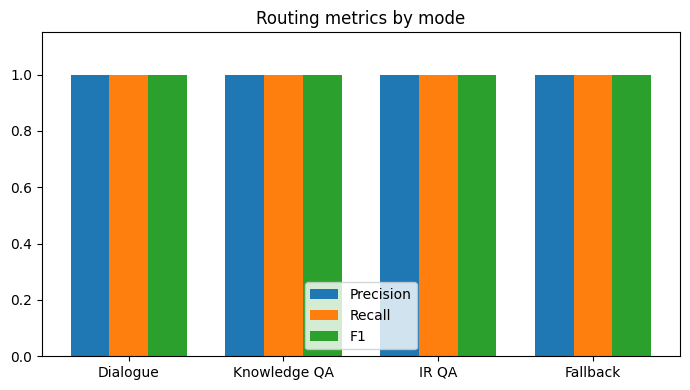

In [5]:
import matplotlib.pyplot as plt
m = metrics[metrics.Mode != 'Macro average']
x = range(len(m)); w = 0.25
fig, ax = plt.subplots(figsize=(7,4))
ax.bar([i-w for i in x], m.Precision, width=w, label='Precision')
ax.bar(x, m.Recall, width=w, label='Recall')
ax.bar([i+w for i in x], m.F1, width=w, label='F1')
ax.set_xticks(list(x)); ax.set_xticklabels(m.Mode)
ax.set_ylim(0,1.15); ax.legend(); ax.set_title('Routing metrics by mode')
plt.tight_layout(); plt.show()

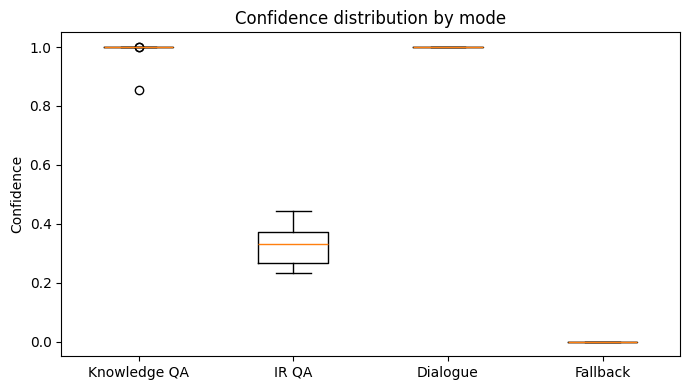

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
groups = [results[results.predicted_mode==md_].confidence for md_ in ['Knowledge QA','IR QA','Dialogue','Fallback']]
ax.boxplot(groups, tick_labels=['Knowledge QA','IR QA','Dialogue','Fallback'])
ax.set_ylabel('Confidence'); ax.set_title('Confidence distribution by mode')
plt.tight_layout(); plt.show()

## Save results to /results

In [7]:
os.makedirs('../results', exist_ok=True)
results.to_csv('../results/evaluation_results.csv', index=False)
metrics.to_csv('../results/per_mode_metrics.csv', index=False)
print('Saved.')

Saved.
